# ДЗ 1. Рекомендательные системы

## 1. Датасет
**KuaiRand-Pure**, два файла обычной выдачи Kuaishou `log_standard_*`.
[Описание](https://kuairand.com/) · [Данные, CC BY-SA 4.0](https://zenodo.org/records/10439422) · [Статья](https://doi.org/10.1145/3511808.3557624).

Рекомендуем новые видео. Берём первый однозначный корректный показ каждой пары.
Релевантность: `play_time_ms >= min(duration_ms, 18000)`, одинаковая для всех моделей.
`time_ms` — Unix-время; `play_time_ms` — просмотр; `duration_ms` — длина видео.
`tag` — обезличенные контентные метки. Запрещённые наборы не используются; список семинарских датасетов неизвестен.

**Запуск:** Python 3.12, зависимости в `requirements.txt`. Перезапустить ядро и выполнить все ячейки сверху вниз.
Архив (~47 МБ) загружается в `.cache/`, проверяется MD5 авторов.

In [1]:
from pathlib import Path
import hashlib
import json
import shutil
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
RAW_DIR = Path('.cache/raw/kuairand')
PREPARED_DIR = Path('.cache/prepared/kuairand')
REPORT_DIR = Path('reports')
FIGURE_DIR = REPORT_DIR / 'figures'
for directory in [RAW_DIR, PREPARED_DIR, REPORT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

In [2]:
SOURCE = {
    'url': 'https://zenodo.org/records/10439422/files/KuaiRand-Pure.tar.gz',
    'md5': '0820331067a3784d9691136f772b35a7',
}
archive_path = RAW_DIR / 'KuaiRand-Pure.tar.gz'
if not archive_path.exists():
    temporary_path = archive_path.with_suffix('.part')
    with urllib.request.urlopen(SOURCE['url'], timeout=180) as response:
        with temporary_path.open('wb') as output:
            shutil.copyfileobj(response, output)
    temporary_path.rename(archive_path)
with archive_path.open('rb') as file:
    assert hashlib.file_digest(file, 'md5').hexdigest() == SOURCE['md5']
print('Архив проверен.')

Архив проверен.


In [3]:
LOG_FILES = [
    'log_standard_4_08_to_4_21_pure.csv',
    'log_standard_4_22_to_5_08_pure.csv',
]
log_frames = []
source_counts = {}
with tarfile.open(archive_path, 'r:gz') as archive:
    for filename in LOG_FILES:
        frame = pd.read_csv(archive.extractfile('KuaiRand-Pure/data/' + filename))
        source_counts[filename] = len(frame)
        log_frames.append(frame)
    metadata = pd.read_csv(archive.extractfile('KuaiRand-Pure/data/video_features_basic_pure.csv'))

raw = pd.concat(log_frames, ignore_index=True)
del log_frames, frame
assert raw.is_rand.eq(0).all(), 'В выбранные файлы попали случайные показы'
assert metadata.video_id.is_unique

display(pd.Series(source_counts, name='События').to_frame())
display(pd.DataFrame({
    'Показатель': ['События', 'Пользователи', 'Видео в логах', 'Видео в метаданных'],
    'Значение': [len(raw), raw.user_id.nunique(), raw.video_id.nunique(), len(metadata)],
}))

,События
log_standard_4_08_to_4_21_pure.csv,1141112
log_standard_4_22_to_5_08_pure.csv,295497


,Показатель,Значение
0,События,1436609
1,Пользователи,27077
2,Видео в логах,7551
3,Видео в метаданных,7583


## 2. Подготовка данных
Проверяем пропуски, дубликаты и некорректные значения. Для времени используем UTC.

In [4]:
missing_fields = raw.isna().sum().rename('Пропуски')
display(pd.Series({
    'Пропуски в логах': int(missing_fields.sum()),
    'Пропуски в метаданных': int(metadata.isna().sum().sum()),
    'Полные дубликаты': int(raw.duplicated().sum()),
    'Повторные пары': int(raw.duplicated(['user_id', 'video_id']).sum()),
    'Некорректная длительность': int(raw.duration_ms.le(0).sum()),
    'Отрицательный просмотр': int(raw.play_time_ms.lt(0).sum()),
    'Показы без метаданных': int((~raw.video_id.isin(metadata.video_id)).sum()),
}, name='Количество').to_frame())

,Количество
Пропуски в логах,0
Пропуски в метаданных,538
Полные дубликаты,21987
Повторные пары,61609
Некорректная длительность,28874
Отрицательный просмотр,0
Показы без метаданных,0


### Очистка
Оставляем корректные ID, время, длительность и флаги. Удаляем полные дубликаты.
Для каждой пары берём первый показ; при разных реакциях в один момент исключаем пару.
Проверяем метаданные, пустые метки заменяем на `Unknown`. По активности не фильтруем.

In [5]:
BINARY_COLUMNS = [
    'is_click', 'is_like', 'is_follow', 'is_comment', 'is_forward',
    'is_hate', 'long_view', 'is_profile_enter', 'is_rand',
]
parsed_time = pd.to_datetime(raw.time_ms, unit='ms', utc=True, errors='coerce')
valid_mask = (
    raw.user_id.ge(0) & raw.video_id.ge(0) & raw.time_ms.gt(0)
    & parsed_time.notna() & raw.duration_ms.gt(0) & raw.play_time_ms.ge(0)
    & raw[BINARY_COLUMNS].isin([0, 1]).all(axis=1)
)
valid = raw.loc[valid_mask].copy()
unique_events = valid.drop_duplicates().copy()
pair_columns = ['user_id', 'video_id']
first_time = unique_events.groupby(pair_columns)['time_ms'].transform('min')
first_events = unique_events.loc[unique_events.time_ms.eq(first_time)].copy()
first_group_size = first_events.groupby(pair_columns)['time_ms'].transform('size')
ambiguous_pairs = first_events.loc[first_group_size.gt(1), pair_columns].drop_duplicates()
first_unambiguous = first_events.loc[first_group_size.eq(1)].copy()
has_metadata = first_unambiguous.video_id.isin(metadata.video_id)
interactions = first_unambiguous.loc[has_metadata].copy()
interactions = interactions.sort_values(['time_ms', 'user_id', 'video_id']).reset_index(drop=True)
interactions['event_time'] = pd.to_datetime(interactions.time_ms, unit='ms', utc=True)
interactions['watch_ratio'] = interactions.play_time_ms / interactions.duration_ms
interactions['is_relevant'] = interactions.play_time_ms.ge(
    interactions.duration_ms.clip(upper=18_000)
).astype('int8')

item_columns = ['video_id', 'author_id', 'video_type', 'upload_dt', 'video_duration', 'tag']
items = metadata.loc[metadata.video_id.isin(interactions.video_id), item_columns].copy()
items['tag'] = items.tag.fillna('Unknown').astype(str)
items = items.sort_values('video_id').reset_index(drop=True)

cleaning = pd.DataFrame([
    ('Исходные события обычной выдачи', len(raw)),
    ('Корректные значения полей', len(valid)),
    ('Без полных дубликатов', len(unique_events)),
    ('Первый однозначный показ пары', len(first_unambiguous)),
    ('Видео с метаданными', len(interactions)),
], columns=['Этап', 'События'])
cleaning['Удалено на этапе'] = cleaning['События'].shift(1) - cleaning['События']
cleaning['Удалено на этапе'] = cleaning['Удалено на этапе'].fillna(0).astype(int)
display(cleaning)
print('Пар с неоднозначным первым показом:', len(ambiguous_pairs))

,Этап,События,Удалено на этапе
0,Исходные события обычной выдачи,1436609,0
1,Корректные значения полей,1407735,28874
2,Без полных дубликатов,1385762,21973
3,Первый однозначный показ пары,1345596,40166
4,Видео с метаданными,1345596,0


Пар с неоднозначным первым показом: 1475


In [6]:
flag_mismatch = interactions.long_view.ne(interactions.is_relevant)
utc_date = interactions.event_time.dt.strftime('%Y%m%d').astype(int)
calendar_mismatch = utc_date.ne(interactions.date)
joined_duration = interactions[['video_id', 'duration_ms']].merge(
    items[['video_id', 'video_duration']], on='video_id', validate='many_to_one'
)
assert joined_duration.duration_ms.eq(joined_duration.video_duration).all()

print('Расхождений long_view с формулой:', flag_mismatch.sum(), f'({flag_mismatch.mean():.3%})')
print('Расхождений date источника с календарным днём UTC:', calendar_mismatch.sum())
print('Длительность в событиях совпадает с длительностью в метаданных.')
print('Период UTC:', interactions.event_time.min(), '—', interactions.event_time.max())
display(interactions[['play_time_ms', 'duration_ms', 'watch_ratio']].quantile(
    [0, 0.5, 0.9, 0.99, 1]
).rename_axis('Квантиль'))

Расхождений long_view с формулой: 3310 (0.246%)
Расхождений date источника с календарным днём UTC: 195486
Длительность в событиях совпадает с длительностью в метаданных.
Период UTC: 2022-04-09 03:46:03.278000+00:00 — 2022-05-08 15:52:10.564000+00:00


,play_time_ms,duration_ms,watch_ratio
Квантиль,,,
0.00,0.00,5000.0,0.000000
0.50,5237.00,73000.0,0.102610
0.90,70263.50,241560.0,1.038548
0.99,214768.05,427633.0,2.095397
1.00,964774.00,1177720.0,62.879752


In [7]:
user_activity = interactions.groupby('user_id').size()
item_popularity = interactions.groupby('video_id').size().sort_values(ascending=False)
daily_counts = interactions.groupby(interactions.event_time.dt.floor('D')).size()
signal_columns = ['is_relevant', 'is_click', 'is_like', 'is_follow', 'is_hate']
signal_rates = interactions[signal_columns].mean()
n_events, n_users, n_items = len(interactions), len(user_activity), len(item_popularity)
density = n_events / (n_users * n_items)
metadata_used = metadata.loc[metadata.video_id.isin(items.video_id)]
summary = {
    'dataset': 'KuaiRand-Pure', 'raw_interactions': len(raw),
    'clean_interactions': n_events, 'users': n_users, 'items': n_items,
    'relevant_share': float(interactions.is_relevant.mean()), 'sparsity': 1 - density,
}
display(pd.Series(summary, name='Значение').to_frame())
display(pd.DataFrame({
    'Видео на пользователя': user_activity.describe(percentiles=[0.5, 0.9, 0.99]),
    'Пользователей на видео': item_popularity.describe(percentiles=[0.5, 0.9, 0.99]),
}).round(2))

,Значение
dataset,KuaiRand-Pure
raw_interactions,1436609
clean_interactions,1345596
users,27058
items,7314
relevant_share,0.340763
sparsity,0.993201


,Видео на пользователя,Пользователей на видео
count,27058.00,7314.00
mean,49.73,183.98
std,46.93,424.87
min,1.00,1.00
50%,37.00,54.00
90%,108.00,466.70
99%,215.00,1859.05
max,823.00,10257.00


### Реакции и время
Реакции пересекаются, сумма долей не обязана равняться 100%.
Пик — 10–11 апреля. Пунктир показывает границу файлов, а не причину изменения объёма.

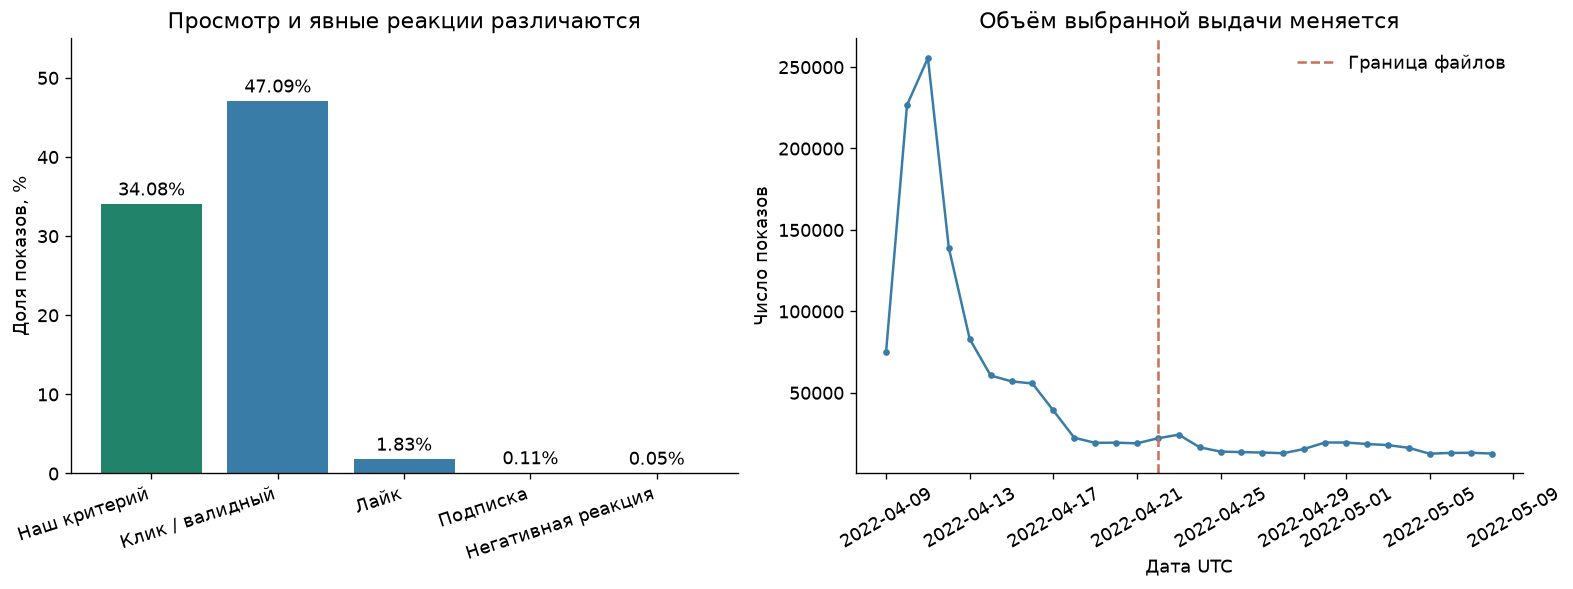

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
labels = ['Наш критерий', 'Клик / валидный', 'Лайк', 'Подписка', 'Негативная реакция']
percentages = signal_rates.values * 100
axes[0].bar(np.arange(len(labels)), percentages, color=['#20836a', '#397ca8', '#397ca8', '#397ca8', '#c77055'])
for position, value in enumerate(percentages):
    axes[0].text(position, value + 0.5, f'{value:.2f}%', ha='center', va='bottom')
axes[0].set_xticks(np.arange(len(labels)), labels, rotation=18, ha='right')
axes[0].set(title='Просмотр и явные реакции различаются', ylabel='Доля показов, %', ylim=(0, 55))

axes[1].plot(daily_counts.index, daily_counts.values, marker='o', markersize=3, color='#397ca8')
axes[1].axvline(pd.Timestamp('2022-04-22', tz='UTC'), color='#c77055', linestyle='--', label='Граница файлов')
axes[1].set(title='Объём выбранной выдачи меняется', xlabel='Дата UTC', ylabel='Число показов')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(frameon=False)
fig.savefig(FIGURE_DIR / '01_feedback_and_time.png', dpi=160)
plt.show()

### Активность
Шкалы логарифмические. Справа видео отсортированы по популярности.

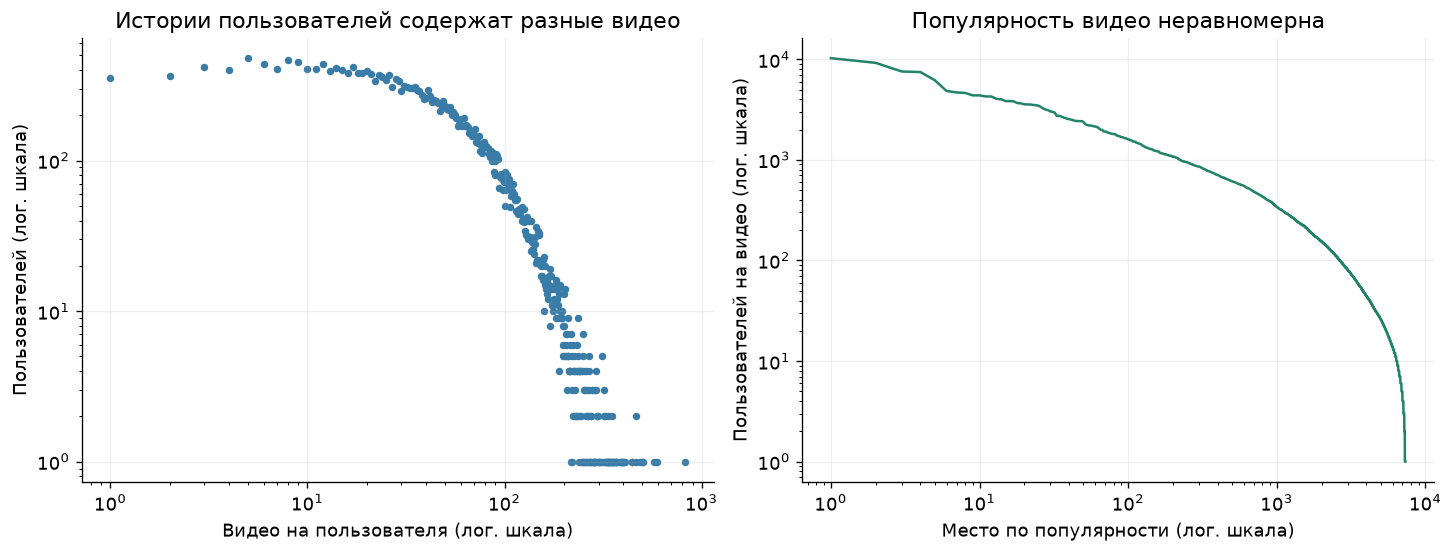

Медиана истории: 37.0 видео.
Одно видео у 1.31% пользователей.
Разреженность: 99.32007%.


In [9]:
activity_distribution = user_activity.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
axes[0].scatter(activity_distribution.index, activity_distribution.values, s=12, color='#397ca8')
axes[0].set(xscale='log', yscale='log', title='Истории пользователей содержат разные видео',
            xlabel='Видео на пользователя (лог. шкала)', ylabel='Пользователей (лог. шкала)')
axes[1].plot(np.arange(1, n_items + 1), item_popularity.values, color='#20836a')
axes[1].set(xscale='log', yscale='log', title='Популярность видео неравномерна',
            xlabel='Место по популярности (лог. шкала)', ylabel='Пользователей на видео (лог. шкала)')
for axis in axes:
    axis.grid(alpha=0.2)
fig.savefig(FIGURE_DIR / '02_activity_and_popularity.png', dpi=160)
plt.show()
print('Медиана истории:', user_activity.median(), 'видео.')
print(f'Одно видео у {user_activity.eq(1).mean():.2%} пользователей.')
print(f'Разреженность: {1 - density:.5%}.')

### Признаки FM
Метки описывают содержание видео, длительность — время просмотра. Считаем метки постоянным описанием контента.
Словари и масштабирование — только по train. Реакции целевого показа и агрегаты за месяц в признаки не входят.

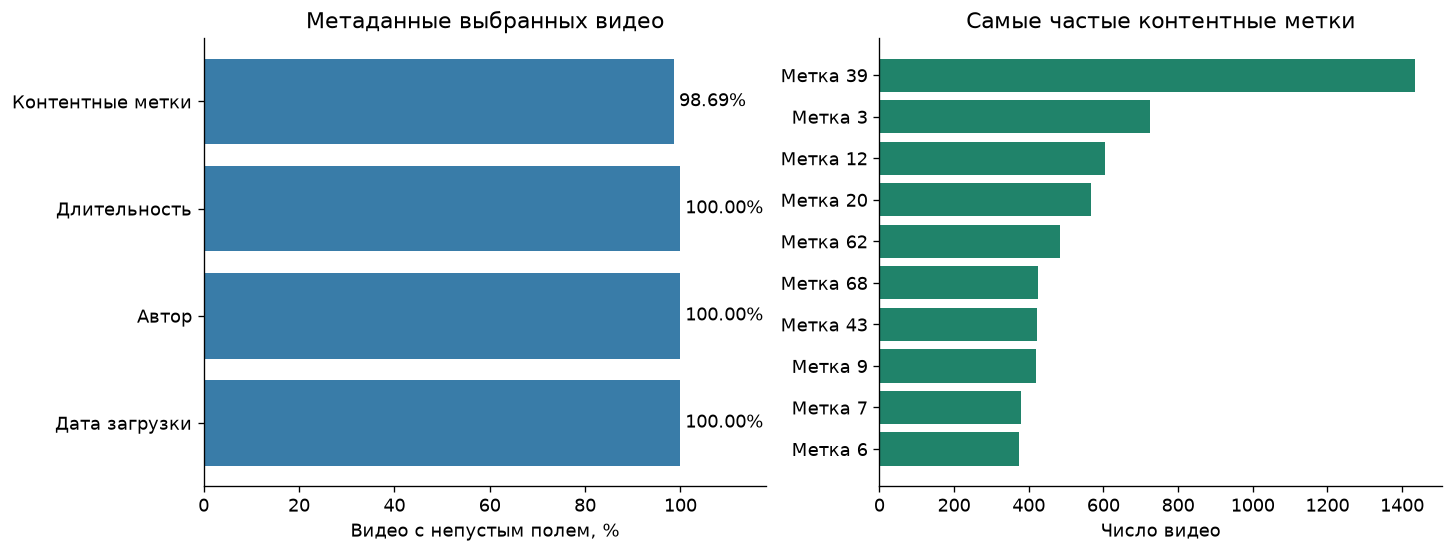

Различных непустых меток: 45
Видео без меток: 96


In [10]:
coverage_fields = ['tag', 'video_duration', 'author_id', 'upload_dt']
coverage = metadata_used[coverage_fields].notna().mean() * 100
coverage.index = ['Контентные метки', 'Длительность', 'Автор', 'Дата загрузки']
tag_rows = items[['video_id', 'tag']].copy()
tag_rows['tag'] = tag_rows.tag.str.split(',')
tag_rows = tag_rows.explode('tag').drop_duplicates(['video_id', 'tag'])
top_tags = tag_rows.loc[tag_rows.tag.ne('Unknown'), 'tag'].value_counts().head(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
axes[0].barh(coverage.index, coverage.values, color='#397ca8')
for row, value in enumerate(coverage.values):
    axes[0].text(value + 1, row, f'{value:.2f}%', va='center')
axes[0].invert_yaxis()
axes[0].set(title='Метаданные выбранных видео', xlabel='Видео с непустым полем, %', xlim=(0, 118))
axes[1].barh(['Метка ' + value for value in top_tags.index], top_tags.values, color='#20836a')
axes[1].set(title='Самые частые контентные метки', xlabel='Число видео')
fig.savefig(FIGURE_DIR / '03_metadata.png', dpi=160)
plt.show()
print('Различных непустых меток:', tag_rows.loc[tag_rows.tag.ne('Unknown'), 'tag'].nunique())
print('Видео без меток:', metadata_used.tag.isna().sum())

In [11]:
assert 100_000 <= n_events <= 2_000_000
assert n_users >= 1_000 and n_items >= 1_000
assert not interactions.duplicated(pair_columns).any()
assert interactions[BINARY_COLUMNS + ['is_relevant']].isin([0, 1]).all().all()
assert interactions.duration_ms.gt(0).all() and interactions.play_time_ms.ge(0).all()
assert np.isfinite(interactions.watch_ratio).all()
assert interactions.event_time.is_monotonic_increasing
assert set(interactions.video_id) == set(items.video_id)
assert user_activity.sum() == item_popularity.sum() == daily_counts.sum() == n_events

export_columns = ['user_id', 'video_id', 'time_ms', 'play_time_ms', 'duration_ms', 'tab']
export_columns += BINARY_COLUMNS + ['watch_ratio', 'is_relevant']
compression = {'method': 'gzip', 'mtime': 0}
interactions[export_columns].to_csv(PREPARED_DIR / 'interactions.csv.gz', index=False, compression=compression)
items.to_csv(PREPARED_DIR / 'items.csv.gz', index=False, compression=compression)
cleaning.to_csv(REPORT_DIR / 'cleaning.csv', index=False)
(REPORT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))

206

## 3. Единый протокол
Границы UTC: train — до 22.04; validation — 22.04–30.04; test — с 01.05.
Словари строим по train. Оцениваем пользователей с положительной train-историей
и хотя бы одним релевантным видео из train-каталога в периоде оценки.

Кандидаты — **весь каталог train**, без семплирования. Исключаем все предыдущие показы:
train для validation, train + validation для test. Модели обучаются только на train;
для финального test переобучение не предусмотрено. При равных оценках первым идёт меньший ID.

Основная метрика — **NDCG@10**, вторая — **Recall@10**, среднее по пользователям.
Recall — доля найденных релевантных видео; NDCG учитывает позиции через `1/log2(rank+1)`.
Неотмеченные в отложенном периоде кандидаты получают релевантность 0; это ограничение офлайн-оценки.
Группы внутри периода одинаковы для всех моделей. Подбор — только по validation.

In [12]:
from protocol import split_and_encode, positive_matrix, make_cohort
from features import build_item_features
from evaluation import recommend_all, ranking_metrics

parts, user_ids, item_ids = split_and_encode(interactions)
train, validation, test = parts['train'], parts['validation'], parts['test']
shape = (len(user_ids), len(item_ids))
positive = positive_matrix(train, shape)
validation_set = make_cohort(validation, train, positive)
test_set = make_cohort(test, pd.concat([train, validation]), positive)
item_features, feature_info = build_item_features(items, item_ids)

split_summary = pd.DataFrame({
    name: {
        'Показы': len(frame),
        'Релевантные': int(frame.is_relevant.sum()),
        'Новые пользователи (показы)': int(frame.u.lt(0).sum()),
        'Новые видео (показы)': int(frame.i.lt(0).sum()),
    }
    for name, frame in parts.items()
}).T
split_summary['Пользователи оценки'] = [0, len(validation_set.users), len(test_set.users)]
display(split_summary)
print('Train-каталог:', shape[1], 'видео. Меток FM:', feature_info['tags'])
split_summary.to_csv(REPORT_DIR / 'split_summary.csv')

,Показы,Релевантные,Новые пользователи (показы),Новые видео (показы),Пользователи оценки
train,1071473,370302,0,0,0
validation,150994,48702,3144,21,16465
test,123129,39526,4555,10,14356


Train-каталог: 7301 видео. Меток FM: 46


In [13]:
assert len(train) + len(validation) + len(test) == len(interactions)
assert train.time_ms.max() < validation.time_ms.min() < test.time_ms.min()
assert validation.time_ms.max() < test.time_ms.min()
assert train.u.ge(0).all() and train.i.ge(0).all()
assert len(user_ids) == train.user_id.nunique()
assert len(item_ids) == train.video_id.nunique()
assert positive.nnz == train.is_relevant.sum()
assert item_features.shape[0] == shape[1]
assert np.isfinite(item_features.data).all()
for cohort in [validation_set, test_set]:
    assert len(cohort.users) > 0
    assert np.all(positive[cohort.users].getnnz(axis=1) > 0)
    assert np.all(cohort.relevant[cohort.users].getnnz(axis=1) > 0)
    assert np.all(shape[1] - cohort.seen[cohort.users].getnnz(axis=1) >= 10)
    assert cohort.seen.multiply(cohort.relevant).nnz == 0

## 4. Модели
$X$ — бинарная матрица положительных просмотров. Все модели используют общий `recommend`.

- **ItemKNN:** косинус $s_{ij}=x_i^Tx_j/(\|x_i\|\|x_j\|)$; оставляем ближайших соседей, $\hat r=X S$.
- **iALS:** $\sum c_{ui}(p_{ui}-U_u^TV_i)^2+\lambda(\|U\|^2+\|V\|^2)$.
  У показов $p=\mathrm{is\_relevant}$, $c=1+\alpha$; у ненаблюдавшихся пар $p=0$, $c=1$.
- **EASE:** $P=(X^TX+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$; диагональ $B$ равна 0, $\hat r=XB$.
- **FM:** $z=b+w^Tx+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k$; обучаем BCE с Adam, ранжируем по $z$.
  Признаки: ID, multi-hot метки и стандартизированный `log1p(duration)`.
- **EngagementALS:** тот же ALS с таргетом `(1−hate)·(0.7·min(watch_ratio,1)+0.2·like+0.1·follow)`.
  Досмотр — основной сигнал, лайк и подписка дополняют его, негативная реакция обнуляет.
  Веса заданы заранее; confidence и общая релевантность не меняются.

Источники: [iALS](https://yifanhu.net/PUB/cf.pdf), [EASE](https://arxiv.org/abs/1905.03375), [FM](https://doi.org/10.1109/ICDM.2010.127).

## 5. Подбор параметров
Перебираем **36 конфигураций** на полном train и всей validation.
Выбор — максимум NDCG@10; при равенстве берём первую конфигурацию. Test не участвует.

| Модель | Пространство поиска | Число |
|---|---|---:|
| ItemKNN | соседи: 20, 50, 100, 200 | 4 |
| iALS | факторы: 16, 32; α: 1, 10; λ: 1, 10 | 8 |
| EASE | λ: 30, 100, 300, 1000 | 4 |
| FM | факторы: 16, 32; λ: 10⁻⁶, 10⁻⁵, 10⁻⁴; эпохи: 3, 10 | 12 |
| EngagementALS | та же сетка, что у iALS | 8 |

Фиксируем seed=42, для ALS — 10 итераций, для FM — lr=0.01 и batch=4096.
Формула собственного таргета неизменна. Сетка небольшая: глобальный оптимум не гарантируется.

In [14]:
from experiment_utils import SEARCH_SPACE, search_models, fit_model, bootstrap_difference

search_results, selected_parameters, selected_models = search_models(
    train, positive, item_features, validation_set, REPORT_DIR,
)
best_rows = search_results.loc[search_results.groupby('model', sort=False)['NDCG@10'].idxmax()]
best_validation = best_rows.set_index('model')
parameter_text = {
    name: ', '.join(f'{key}={parameters[key]}' for key in SEARCH_SPACE[name])
    for name, parameters in selected_parameters.items()
}
selection_table = best_validation[['NDCG@10', 'Recall@10']].copy()
selection_table['Параметры'] = pd.Series(parameter_text)
with pd.option_context('display.max_colwidth', None):
    display(selection_table.round(5))

ItemKNN: 4 настроек, NDCG@10 = 0.05934


iALS: 8 настроек, NDCG@10 = 0.04709


EASE: 4 настроек, NDCG@10 = 0.06431


FM: 12 настроек, NDCG@10 = 0.00801


EngagementALS: 8 настроек, NDCG@10 = 0.04495


,NDCG@10,Recall@10,Параметры
model,,,
ItemKNN,0.05934,0.08346,neighbors=200
iALS,0.04709,0.06950,"factors=16, alpha=1, regularization=10"
EASE,0.06431,0.09453,regularization=300
FM,0.00801,0.01094,"factors=32, regularization=1e-06, epochs=10"
EngagementALS,0.04495,0.06658,"factors=16, alpha=1, regularization=10"


## 6. Итоговый test
Настройки выбраны по validation и сохранены до test. Обучение остаётся на train.
У двух ALS выбраны одинаковые параметры — их сравнение проверяет замену таргета.
Для FM дополнительно убираем метаданные при тех же параметрах.

In [15]:
from scipy import sparse

assert selected_parameters['iALS'] == selected_parameters['EngagementALS']
fm_ids = fit_model('FM', selected_parameters['FM'], train, positive,
                   sparse.eye(shape[1], format='csr'))
final_models = {**selected_models, 'FM_ID_only': fm_ids}
validation_leaders = best_validation['NDCG@10'].nlargest(2).index.tolist()

test_per_user, test_recommendations = {}, {}
for name, model in final_models.items():
    recommended = recommend_all(model, test_set)
    metrics = ranking_metrics(recommended, test_set.relevant[test_set.users])
    test_per_user[name] = pd.DataFrame(metrics, index=test_set.users)
    test_recommendations[name] = recommended

test_scores = pd.DataFrame({name: values.mean() for name, values in test_per_user.items()}).T
final_table = test_scores.loc[list(selected_models)].copy()
final_table['Параметры'] = pd.Series(parameter_text)
final_table.to_csv(REPORT_DIR / 'test_results.csv')
test_scores.to_csv(REPORT_DIR / 'test_all_models.csv')
with pd.option_context('display.max_colwidth', None):
    display(final_table.round(5))

# Рекомендации нужны независимому аудиту; в Git они не входят.
result_cache = Path('.cache/results')
result_cache.mkdir(exist_ok=True)
np.savez_compressed(result_cache / 'test_recommendations.npz',
                    users=test_set.users, item_ids=item_ids, **test_recommendations)
pd.concat(test_per_user, names=['model', 'u']).to_csv(result_cache / 'test_per_user.csv.gz')

,NDCG@10,Recall@10,Параметры
ItemKNN,0.05078,0.07623,neighbors=200
iALS,0.04185,0.06571,"factors=16, alpha=1, regularization=10"
EASE,0.05497,0.08603,regularization=300
FM,0.00779,0.01163,"factors=32, regularization=1e-06, epochs=10"
EngagementALS,0.04140,0.06176,"factors=16, alpha=1, regularization=10"


In [16]:
# Парные интервалы используют одни и те же test-пользователей в обоих методах.
comparisons = [
    ('Метаданные FM', 'FM', 'FM_ID_only'),
    ('Собственный таргет, равные настройки', 'EngagementALS', 'iALS'),
    ('Лидеры validation', validation_leaders[0], validation_leaders[1]),
]
comparison_rows = []
for label, first, second in comparisons:
    for metric in ['NDCG@10', 'Recall@10']:
        interval = bootstrap_difference(test_per_user[first][metric], test_per_user[second][metric], seed=SEED)
        comparison_rows.append({'comparison': label, 'first': first, 'second': second,
                                'metric': metric, **interval})
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(REPORT_DIR / 'test_comparisons.csv', index=False)

interval_rows = []
for name in selected_models:
    for metric in ['NDCG@10', 'Recall@10']:
        interval = bootstrap_difference(test_per_user[name][metric], np.zeros(len(test_set.users)), seed=SEED)
        interval_rows.append({'model': name, 'metric': metric, **interval})
intervals = pd.DataFrame(interval_rows).set_index(['model', 'metric'])
intervals.to_csv(REPORT_DIR / 'test_intervals.csv')
display(comparison_table[['comparison', 'metric', 'difference', 'lower_95', 'upper_95']].round(5))

,comparison,metric,difference,lower_95,upper_95
0,Метаданные FM,NDCG@10,-0.00462,-0.00602,-0.00319
1,Метаданные FM,Recall@10,-0.00617,-0.00826,-0.00400
2,"Собственный таргет, равные настройки",NDCG@10,-0.00045,-0.00256,0.00149
3,"Собственный таргет, равные настройки",Recall@10,-0.00394,-0.00703,-0.00088
4,Лидеры validation,NDCG@10,0.00420,0.00243,0.00585
5,Лидеры validation,Recall@10,0.00980,0.00679,0.01267


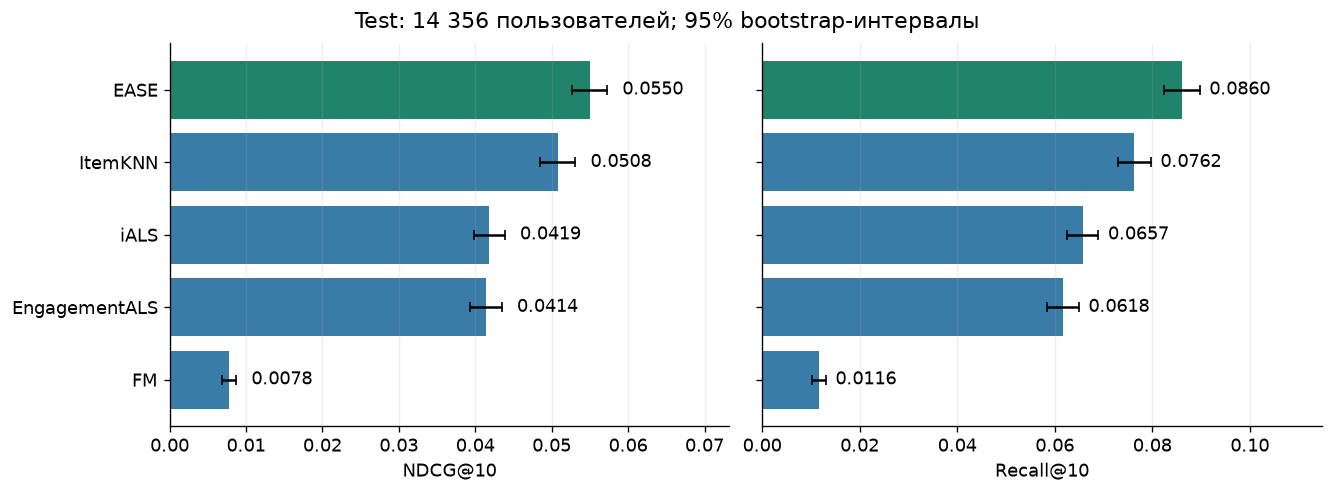

In [17]:
order = final_table['NDCG@10'].sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout='constrained')
for axis, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    means = final_table.loc[order, metric].to_numpy()
    bounds = intervals.xs(metric, level='metric').loc[order]
    errors = np.vstack([means - bounds.lower_95, bounds.upper_95 - means])
    colors = ['#20836a'] + ['#397ca8'] * (len(order) - 1)
    axis.barh(np.arange(len(order)), means, xerr=errors, capsize=3, color=colors)
    for row, value in enumerate(means):
        axis.text(bounds.upper_95.iloc[row] + 0.002, row, f'{value:.4f}', va='center')
    axis.set(yticks=np.arange(len(order)), yticklabels=order, xlabel=metric,
             xlim=(0, bounds.upper_95.max() * 1.28))
    axis.grid(axis='x', alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle(f'Test: {len(test_set.users):,} пользователей; 95% bootstrap-интервалы'.replace(',', ' '))
fig.savefig(FIGURE_DIR / '04_test_comparison.png', dpi=160)
plt.show()

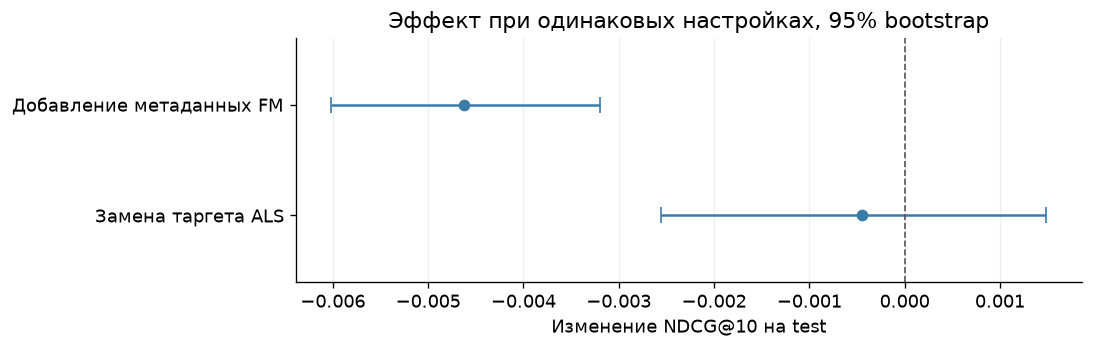

In [18]:
effects = comparison_table.loc[
    comparison_table.metric.eq('NDCG@10') & comparison_table.comparison.ne('Лидеры validation')
].reset_index(drop=True)
fig, axis = plt.subplots(figsize=(9, 2.8), layout='constrained')
for row, effect in effects.iterrows():
    axis.errorbar(effect.difference, row,
                  xerr=[[effect.difference - effect.lower_95], [effect.upper_95 - effect.difference]],
                  fmt='o', capsize=5, color='#397ca8')
axis.axvline(0, color='#555555', linestyle='--', linewidth=1)
axis.set(yticks=[0, 1], yticklabels=['Добавление метаданных FM', 'Замена таргета ALS'],
         xlabel='Изменение NDCG@10 на test', title='Эффект при одинаковых настройках, 95% bootstrap')
axis.set_ylim(-0.6, 1.6)
axis.invert_yaxis()
axis.grid(axis='x', alpha=0.2)
fig.savefig(FIGURE_DIR / '05_controlled_effects.png', dpi=160)
plt.show()

**Выводы:** EASE — лучший на test: NDCG@10 = 0,05497, Recall@10 = 0,08603.
Метаданные ухудшили FM на выбранных настройках. У собственного таргета интервал изменения NDCG содержит ноль;
улучшение не подтверждено, Recall снизился на 0,00394.

Интервалы учитывают вариацию пользователей, а не инициализаций моделей. Результат относится к выбранным
сетке и разбиению. Истории неполные, обычная выдача смещена, разметка непоказанных видео неизвестна;
холодный старт не оценивается.